In [49]:
# 그래프 관련
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
# matplotlib.rcParams['font.family'] = 'AppleGothic'
matplotlib.rcParams['axes.unicode_minus']=False

import pandas as pd
import numpy as np

# 머신러닝 관련
from sklearn import svm,metrics
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier  #평균절대값오차
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error

In [50]:
df = pd.read_csv('data/score.csv')

In [51]:
hour = np.array(df['hour']).reshape(-1, 1)
score = np.array(df['score'])

In [52]:
train_data,test_data,train_label,test_label = \
    train_test_split(hour,score)

In [53]:
train_poly = np.column_stack((train_data**2, train_data))
test_poly = np.column_stack((test_data**2, test_data))
test_poly[:2]

array([[ 5.76,  2.4 ],
       [36.  ,  6.  ]])

In [54]:
lr = LinearRegression()
lr.fit(train_poly, train_label)
predict = lr.predict(test_poly)
print('점수예측: ', predict)
score = lr.score(train_poly, train_label)
score2 = lr.score(test_poly, test_label)
print(f'정확도:{score*100}%, {score2*100}%')

점수예측:  [24.65655437 63.14011917 33.56907013 75.04068489 52.8688081 ]
정확도:95.20154140403741%, 97.68220765744485%


In [65]:
i_data = input('공부시간 입력(예: 7(시간))')
i_data = float(i_data)
predict = lr.predict([[i_data**2, i_data]])
print('점수 예측: ', predict)

점수 예측:  [63.14011917]


In [66]:
i_data2 = input('공부시간 입력(예: 7(시간))')
i_data2 = float(i_data2)
predict2 = lr.predict([[i_data2**2, i_data2]])
print('점수 예측: ', predict2)

점수 예측:  [82.71681505]


In [67]:
point = np.arange(1,11,0.1)

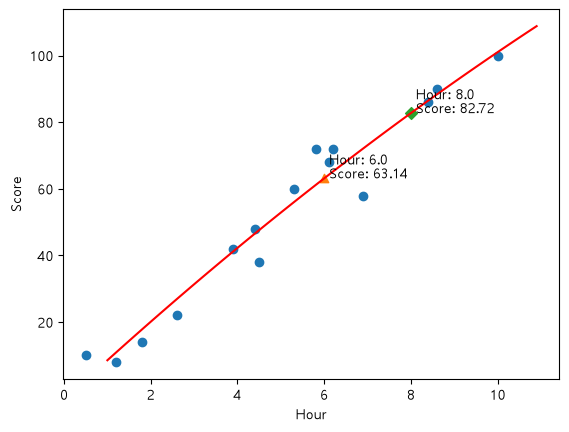

In [68]:
# 그래프 그리기
plt.scatter(train_data,train_label)
plt.scatter(i_data,predict, marker='^')
plt.scatter(i_data2,predict2, marker='D')
plt.plot(point,point**2*lr.coef_[0]+point*lr.coef_[1]+lr.intercept_, color='red')
plt.text(i_data, predict[0], f' Hour: {i_data}\n Score: {predict[0]:.2f}')
plt.text(i_data2, predict2[0], f' Hour: {i_data2}\n Score: {predict2[0]:.2f}')
plt.xlabel('Hour')
plt.ylabel('Score')
plt.show()